# 04 — Application: savings vs home-biased vs global

Goal: compare long-run wealth outcomes for an Australian investor holding savings, a home-biased equity
portfolio, or a globally diversified one, under the real-world measure $\mathbb{P}$; then test how sensitive
the conclusions are to estimation error and to GBM itself.

**Setup.** A fraction $\pi$ of wealth is in equities, split $w$ in Australia (VAS) and $1-w$ global (VGS);
the rest is in savings at the constant rate $r$; the portfolio is rebalanced continuously. Wealth is then a
GBM with

$$\mu_p = r + \pi\big(w\mu_A + (1-w)\mu_G - r\big), \qquad \sigma_p^2 = \pi^2\big(w^2\sigma_A^2 + (1-w)^2\sigma_G^2 + 2w(1-w)\rho\,\sigma_A\sigma_G\big)$$

so that

$$\ln\frac{W_T}{W_0} \sim \mathcal{N}\left(\left(\mu_p - \tfrac12\sigma_p^2\right)T,\ \sigma_p^2 T\right), \qquad \mathbb{P}\left(W_T < W_0 e^{rT}\right) = \Phi\left(-\frac{\left(\mu_p - r - \tfrac12\sigma_p^2\right)\sqrt{T}}{\sigma_p}\right).$$

The portfolio formulas use $\mu$ (the drift of price); median and quantiles of wealth use
$\nu_p = \mu_p - \tfrac12\sigma_p^2$. Parameters are the full-sample estimates of notebook 03 (Table 3).

Outputs: Figs 9–12, Table 4 (`tables/portfolio_outcomes.*`), and supporting tables
(`tables/portfolio_*.csv`).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats

import config as cfg
from src import gbm_utils as gu

gu.set_style()
pd.set_option("display.width", 160)
KEYS = list(cfg.TICKERS)
DT = cfg.DT
r = cfg.R_ANNUAL
W0 = cfg.W0
H = np.array(cfg.HORIZONS, dtype=float)

daily = pd.read_csv(gu.CLEAN_DIR / "log_returns.csv", index_col="date", parse_dates=True)[KEYS]
X = daily.to_numpy()
table3 = pd.read_csv(gu.TAB_DIR / "estimates.csv", index_col="parameter")
post = pd.read_csv(gu.CLEAN_DIR / "posterior_gbm.csv")

mu_a, mu_g = table3.loc["mu_AU", "estimate"], table3.loc["mu_GL", "estimate"]
s_a, s_g = table3.loc["sigma_AU", "estimate"], table3.loc["sigma_GL", "estimate"]
rho = table3.loc["rho", "estimate"]
print(f"r = {r:.4%} continuously compounded ({cfg.R_SOURCE})")
print(f"mu_A = {mu_a:.4%}, mu_G = {mu_g:.4%}, sigma_A = {s_a:.4%}, sigma_G = {s_g:.4%}, rho = {rho:.4f}")
print(f"W0 = {W0:,} AUD; horizons {cfg.HORIZONS} years")

r = 4.7361% continuously compounded (RBA cash rate target 4.85% p.a., effective 4 Nov 2026)
mu_A = 9.1903%, mu_G = 13.1092%, sigma_A = 14.6545%, sigma_G = 13.1307%, rho = 0.5855
W0 = 10,000 AUD; horizons [1, 5, 10, 20, 30] years


## 1. Portfolios

Weights are set in `config.py` with their sources. The minimum-variance weight minimises $\sigma_p$ over $w$
for $\pi = 1$:

$$w^* = \frac{\sigma_G^2 - \rho\,\sigma_A\sigma_G}{\sigma_A^2 + \sigma_G^2 - 2\rho\,\sigma_A\sigma_G}.$$

In [2]:
w_star = gu.min_variance_weight(s_a, s_g, rho)
w_star_used = float(np.clip(w_star, 0, 1))
print(f"Minimum-variance AU weight w* = {w_star:.4f}" + ("" if w_star == w_star_used else f" (clipped to {w_star_used})"))

PORTS = {                                      # name: (pi, w, note)
    "Savings": (0.0, 0.0, f"r = {r:.2%} (cont.); {cfg.R_SOURCE}"),
    "All Australian": (1.0, 1.0, "w = 1: extreme home bias"),
    "Home-biased": (1.0, cfg.W_HOME_BIASED, cfg.W_HOME_BIASED_SOURCE),
    "Market-cap": (1.0, cfg.W_MARKET_CAP, cfg.W_MARKET_CAP_SOURCE),
    "Minimum variance": (1.0, w_star_used, "w* from notebook 03 estimates"),
}
RISKY = [p for p in PORTS if p != "Savings"]
COL = cfg.PORT_COLORS
LS = {p: ("--" if p == "Minimum variance" else "-") for p in PORTS}

rows = []
for p, (pi, w, note) in PORTS.items():
    mp, sp = gu.portfolio_params(pi, w, mu_a, mu_g, s_a, s_g, rho, r)
    rows.append({"portfolio": p, "pi": pi, "w (AU share)": w if pi > 0 else np.nan,
                 "mu_p": mp, "sigma_p": sp, "nu_p": mp - sp**2 / 2, "source / note": note})
port_tab = pd.DataFrame(rows).set_index("portfolio")
port_tab.to_csv(gu.TAB_DIR / "portfolio_parameters.csv")
with pd.option_context("display.max_colwidth", 70):
    display(port_tab.style.format({"pi": "{:.2f}", "w (AU share)": "{:.4f}", "mu_p": "{:.4%}",
                                   "sigma_p": "{:.4%}", "nu_p": "{:.4%}"}, na_rep="--"))

Minimum-variance AU weight w* = 0.3692


,pi,w (AU share),mu_p,sigma_p,nu_p,source / note
portfolio,,,,,,
Savings,0.00,--,4.7361%,0.0000%,4.7361%,"r = 4.74% (cont.); RBA cash rate target 4.85% p.a., effective 4 Nov 2026"
All Australian,1.00,1.0000,9.1903%,14.6545%,8.1165%,w = 1: extreme home bias
Home-biased,1.00,0.3333,11.8029%,12.2703%,11.0501%,"Anarkulova, Cederburg and O'Doherty (2026), SSRN 4590406: optimal split ~1/3 domestic, 2/3 international equities"
Market-cap,1.00,0.0160,13.0465%,13.0592%,12.1938%,"MSCI World vs MSCI World ex Australia (AUD) index factsheets, 30 Oct 2026: 1.60%"
Minimum variance,1.00,0.3692,11.6623%,12.2618%,10.9106%,w* from notebook 03 estimates


**Uncertainty in the all-equity portfolios.** $\sigma_p(w)$ for $\pi = 1$ depends on $\sigma_A$, $\sigma_G$ and
$\rho$, which are estimated. Its uncertainty is measured in two ways:

- **Block bootstrap** (the robust intervals of notebook 03): the same moving-block bootstrap of the daily
  returns (20-day blocks, 5,000 resamples, same seed, so the same resamples as Table 3); $\sigma_p(w)$ is
  recomputed for every resample and every $w$. This allows for the fat tails and volatility clustering found
  in notebook 02.
- **Bayesian posterior** under i.i.d. GBM (notebook 03b), using the posterior draws of
  $(\sigma_A, \sigma_G, \rho)$.

The 95% band at each $w$ is the 2.5th–97.5th percentile across draws (pointwise). The minimum-variance
weight $w^*$ is recomputed for every bootstrap resample to give a 95% interval for $w^*$.

In [3]:
rng_b = np.random.default_rng(cfg.SEED)
boot = gu.bootstrap_gbm_stats(X, DT, cfg.BLOCK_LENGTH, cfg.N_BOOT, rng_b)      # same resamples as notebook 03
wg = np.linspace(0, 1, 401)
_, sig_curve = gu.portfolio_params(1.0, wg, mu_a, mu_g, s_a, s_g, rho, r)


def sigma_band(sa, sg, rh):
    # pointwise 2.5% / 97.5% of sigma_p(w) over parameter draws
    _, sp = gu.portfolio_params(1.0, wg[None, :], 0, 0, sa[:, None], sg[:, None], rh[:, None], 0)
    return np.quantile(sp, [0.025, 0.975], axis=0)


band_boot = sigma_band(boot.sigma_0.to_numpy(), boot.sigma_1.to_numpy(), boot.rho.to_numpy())
band_post = sigma_band(post.sigma_AU.to_numpy(), post.sigma_GL.to_numpy(), post.rho.to_numpy())
w_star_boot = np.clip(gu.min_variance_weight(boot.sigma_0, boot.sigma_1, boot.rho), 0, 1)
w_star_ci = np.quantile(w_star_boot, [0.025, 0.975])
print(f"Minimum-variance weight w* = {w_star_used:.1%}, block-bootstrap 95% interval "
      f"[{w_star_ci[0]:.1%}, {w_star_ci[1]:.1%}]")

unc_rows = []
for p in RISKY:
    w = PORTS[p][1]
    i = int(np.argmin(abs(wg - w)))
    unc_rows.append({"portfolio": p, "w": w, "sigma_p": port_tab.loc[p, "sigma_p"],
                     "bootstrap 2.5%": band_boot[0, i], "bootstrap 97.5%": band_boot[1, i],
                     "posterior 2.5%": band_post[0, i], "posterior 97.5%": band_post[1, i]})
unc = pd.DataFrame(unc_rows).set_index("portfolio")
unc.to_csv(gu.TAB_DIR / "portfolio_sigma_uncertainty.csv")
unc.style.format("{:.2%}")

Minimum-variance weight w* = 36.9%, block-bootstrap 95% interval [27.6%, 47.9%]


,w,sigma_p,bootstrap 2.5%,bootstrap 97.5%,posterior 2.5%,posterior 97.5%
portfolio,,,,,,
All Australian,100.00%,14.65%,12.77%,17.12%,14.30%,15.04%
Home-biased,33.33%,12.27%,11.10%,13.55%,11.97%,12.59%
Market-cap,1.60%,13.06%,11.90%,14.29%,12.74%,13.40%
Minimum variance,36.92%,12.26%,11.08%,13.56%,11.96%,12.58%


**Fig 9** plots the annualised volatility $\sigma_p$ of the all-equity portfolio ($\pi = 1$) against the
Australian share $w$. The shaded region is the 95% block-bootstrap band, the dashed lines the 95% band from
the i.i.d. Bayesian posterior, and the dotted line the volatility if the two markets were perfectly
correlated ($\rho = 1$, no diversification). Markers show the market-cap, home-biased, minimum-variance and
all-Australian portfolios; the horizontal bar on the minimum-variance marker is the bootstrap 95% interval
for $w^*$.

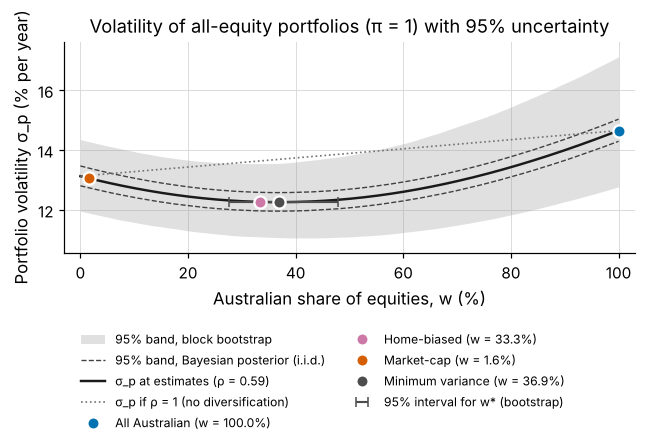

In [4]:
sig_nodiv = wg * s_a + (1 - wg) * s_g
fig, ax = plt.subplots(figsize=(6.0, 4.0))
ax.fill_between(100 * wg, 100 * band_boot[0], 100 * band_boot[1], color="0.6", alpha=0.3, lw=0,
                label="95% band, block bootstrap")
for j in range(2):
    ax.plot(100 * wg, 100 * band_post[j], color="0.25", lw=0.9, ls="--",
            label="95% band, Bayesian posterior (i.i.d.)" if j == 0 else None)
ax.plot(100 * wg, 100 * sig_curve, color="0.1", lw=1.6, label=f"σ_p at estimates (ρ = {rho:.2f})")
ax.plot(100 * wg, 100 * sig_nodiv, color="0.45", lw=1.1, ls=":", label="σ_p if ρ = 1 (no diversification)")
ys = 100 * port_tab.loc["Minimum variance", "sigma_p"]
ax.errorbar(100 * w_star_used, ys, xerr=[[100 * (w_star_used - w_star_ci[0])], [100 * (w_star_ci[1] - w_star_used)]],
            fmt="none", ecolor=COL["Minimum variance"], elinewidth=1.4, capsize=3, zorder=4,
            label="95% interval for w* (bootstrap)")
for p in RISKY:
    w = PORTS[p][1]
    ax.plot(100 * w, 100 * port_tab.loc[p, "sigma_p"], "o", ms=8, color=COL[p], mec="white", mew=1.5, zorder=5,
            label=f"{p} (w = {100 * w:.1f}%)")
ax.set_xlabel("Australian share of equities, w (%)")
ax.set_ylabel("Portfolio volatility σ_p (% per year)")
ax.set_title("Volatility of all-equity portfolios (π = 1) with 95% uncertainty")
ax.set_xlim(-3, 103)
ax.set_ylim(100 * band_boot[0].min() - 0.5, 100 * max(band_boot[1].max(), sig_nodiv.max()) + 0.5)
handles, labels = ax.get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.25, 1, 1))
gu.savefig(fig, "fig09_volatility_vs_weight")
plt.show()

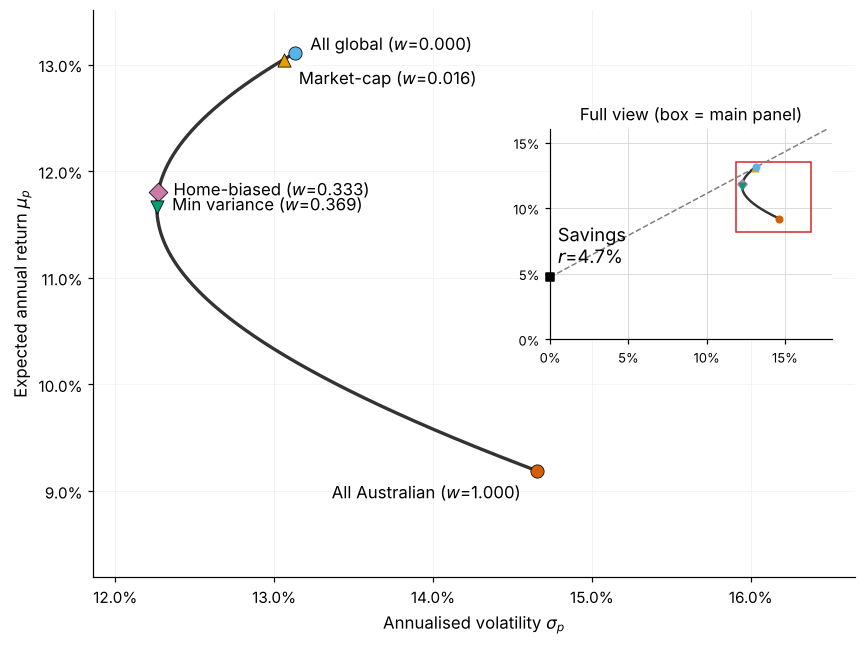

Min-variance w* = 0.369; max-Sharpe w (no shorting) = 0.000
All Australian  w= 1.00  mu_p= 9.19%  sigma_p=14.65%  Sharpe= 0.30
Home-biased     w= 0.33  mu_p=11.80%  sigma_p=12.27%  Sharpe= 0.58
Min variance    w= 0.37  mu_p=11.66%  sigma_p=12.26%  Sharpe= 0.56
Market-cap      w= 0.02  mu_p=13.05%  sigma_p=13.06%  Sharpe= 0.64
All global      w= 0.00  mu_p=13.11%  sigma_p=13.13%  Sharpe= 0.64


In [5]:
w_home = PORTS["Home-biased"][1]
w_mcap = PORTS["Market-cap"][1]

# ---- portfolio maths ------------------------------------------------------
def port(w, pi=1.0):
    """(sigma_p, mu_p) for fraction pi in equities, split w in AU and 1-w global."""
    mu = r + pi * (w * mu_a + (1 - w) * mu_g - r)
    var = (w**2 * s_a**2 + (1 - w)**2 * s_g**2
           + 2 * w * (1 - w) * rho * s_a * s_g)
    return pi * np.sqrt(var), mu

cov = rho * s_a * s_g
w_mv = (s_g**2 - cov) / (s_a**2 + s_g**2 - 2 * cov)   # minimum variance

w_grid = np.linspace(0, 1, 1001)                                # no short sales
sig_f, mu_f = port(w_grid)
sharpe = (mu_f - r) / sig_f
w_tan = w_grid[np.argmax(sharpe)]                               # max Sharpe, 0 <= w <= 1
sig_t, mu_t = port(w_tan)

key = {   # label: (w, marker, colour)
    "All Australian":   (1.0,    "o", "#D55E00"),
    "Home-biased":      (w_home, "D", "#CC79A7"),
    "Min variance":     (w_mv,   "v", "#009E73"),
    "Market-cap":       (w_mcap, "^", "#E69F00"),
    "All global":       (0.0,    "o", "#56B4E9"),
}

if 0.005 < w_tan < 0.995:   # only show separately if it is not a corner portfolio
    key["Max Sharpe"] = (w_tan, "*", "#0072B2")

# ---- figure ---------------------------------------------------------------
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(8, 6))

# Main panel: zoom on the AU/global equity mixes, with direct labels
ax.plot(sig_f, mu_f, color="0.2", lw=2.2)
offsets = {"All Australian": (-10, -18), "Home-biased": (10, -2), "Min variance": (10, -2),
           "Max Sharpe": (10, 4), "Market-cap": (10, -16), "All global": (10, 2)}
for lab, (w, m, c) in key.items():
    x, y = port(w)
    ax.scatter(x, y, marker=m, s=160 if m == "*" else 75, color=c, zorder=5,
               edgecolor="k", linewidth=0.5)
    ax.annotate(f"{lab} ($w$={w:.3f})", (x, y), xytext=offsets[lab],
                textcoords="offset points", fontsize=11,
                ha="right" if offsets[lab][0] < 0 else "left")
pad = 0.004
xlim = (sig_f.min() - pad, sig_f.max() + 5 * pad)
ylim = (mu_f.min() - 2.5 * pad, mu_f.max() + pad)
ax.set_xlim(*xlim); ax.set_ylim(*ylim)
ax.set_xlabel(r"Annualised volatility $\sigma_p$")
ax.set_ylabel(r"Expected annual return $\mu_p$")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.1%}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.1%}")
ax.grid(alpha=0.3)
# ax.set_title(r"Fig 9. Return–volatility of AU/global equity mixes under $\mathbb{P}$"
#             "\n" r"(weight $w$ in Australian equities; GBM estimates)", fontsize=13)

# Inset: miniature view placing savings relative to the frontier
ins = ax.inset_axes([0.60, 0.42, 0.37, 0.37])
s_line = np.linspace(0, 0.18, 50)
ins.plot(s_line, r + sharpe.max() * s_line, "--", color="0.5", lw=1)
ins.plot(sig_f, mu_f, color="0.2", lw=1.6)
ins.scatter(0, r, marker="s", s=30, color="k", zorder=5, clip_on=False)
ins.annotate(f"Savings\n$r$={r:.1%}", (0, r), xytext=(5, 9), textcoords="offset points", fontsize=12)
for lab, (w, m, c) in key.items():
    ins.scatter(*port(w), marker=m, s=18, color=c, zorder=5)
ins.add_patch(Rectangle((xlim[0], ylim[0]), xlim[1] - xlim[0], ylim[1] - ylim[0],
                        fill=False, ec="C3", lw=1, ls="-"))
ins.set_xlim(0, 0.18); ins.set_ylim(0, 0.16)
ins.xaxis.set_major_locator(plt.MultipleLocator(0.05))
ins.yaxis.set_major_locator(plt.MultipleLocator(0.05))
ins.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ins.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ins.tick_params(labelsize=8.5)
ins.set_title("Full view (box = main panel)", fontsize=11)
ins.set_facecolor("white")

fig.tight_layout()
gu.savefig(fig, "fig09_return_volatility")
plt.show()

print(f"Min-variance w* = {w_mv:.3f}; max-Sharpe w (no shorting) = {w_tan:.3f}")
for lab, (w, *_ ) in key.items():
    sp, mp = port(w)
    print(f"{lab:15s} w={w:5.2f}  mu_p={mp:6.2%}  sigma_p={sp:6.2%}  Sharpe={(mp-r)/sp:5.2f}")

**Fig 9c: uncertainty of the all-equity portfolios in the return–volatility plane.** For each $w$ the block
bootstrap of notebook 03 (20-day blocks, 5,000 resamples, same seed) gives draws of
$(\sigma_p(w), \mu_p(w))$ for $\pi = 1$. Their covariance defines a 95% confidence ellipse centred at the point
estimate (radius $\chi^2_2(0.95)$ in Mahalanobis distance). The shaded region is the union of these ellipses
over $w \in [0, 1]$; outlines show the ellipses of the all-Australian, home-biased and market-cap portfolios.
The dotted horizontal line is the savings rate $r$. The ellipses are pointwise (one portfolio at a time).

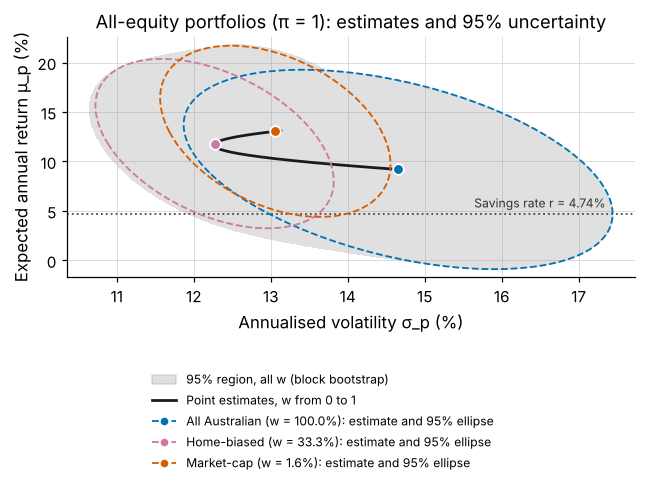

Lowest mu_p inside the 95% region: -0.85% (savings rate r = 4.74%)


,w,mu_p 2.5%,mu_p 97.5%,sigma_p 2.5%,sigma_p 97.5%,"corr(sigma_p, mu_p)",P(mu_p < r)
portfolio,,,,,,,
All Australian,100.00%,0.65%,16.85%,12.77%,17.12%,-0.45,13.60%
Home-biased,33.33%,4.56%,18.37%,11.10%,13.55%,-0.44,2.80%
Market-cap,1.60%,5.61%,19.65%,11.90%,14.28%,-0.39,1.46%
Minimum variance,36.92%,4.46%,18.25%,11.08%,13.56%,-0.45,3.00%


In [6]:
from scipy.stats import chi2
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

w_reg = np.linspace(0, 1, 201)
bmu_a, bmu_g = boot.mu_0.to_numpy(), boot.mu_1.to_numpy()
bs_a, bs_g, brho = boot.sigma_0.to_numpy(), boot.sigma_1.to_numpy(), boot.rho.to_numpy()


def boot_draws(w):
    # bootstrap draws of (sigma_p, mu_p) for pi = 1 at AU weight w
    mp, sp = gu.portfolio_params(1.0, w, bmu_a, bmu_g, bs_a, bs_g, brho, r)
    return sp, mp


centres = np.array([gu.portfolio_params(1.0, w, mu_a, mu_g, s_a, s_g, rho, r)[::-1] for w in w_reg])  # (sigma, mu)
covs = np.array([np.cov(*boot_draws(w)) for w in w_reg])
q95 = chi2.ppf(0.95, 2)
sd = np.sqrt(covs[:, [0, 1], [0, 1]])
S, M = np.meshgrid(np.linspace((centres[:, 0] - 3 * sd[:, 0]).min(), (centres[:, 0] + 3 * sd[:, 0]).max(), 500),
                   np.linspace((centres[:, 1] - 3 * sd[:, 1]).min(), (centres[:, 1] + 3 * sd[:, 1]).max(), 500))
inside = np.zeros(S.shape, dtype=bool)
for (cs, cm), C in zip(centres, covs):
    Ci = np.linalg.inv(C)
    ds, dm = S - cs, M - cm
    inside |= (Ci[0, 0] * ds**2 + 2 * Ci[0, 1] * ds * dm + Ci[1, 1] * dm**2) <= q95


def ellipse_xy(centre, C, n=200):
    vals, vecs = np.linalg.eigh(C)
    t = np.linspace(0, 2 * np.pi, n)
    pts = vecs @ (np.sqrt(vals * q95)[:, None] * np.vstack([np.cos(t), np.sin(t)]))
    return centre[0] + pts[0], centre[1] + pts[1]


fig, ax = plt.subplots(figsize=(6.0, 4.4))
ax.contourf(100 * S, 100 * M, inside.astype(float), levels=[0.5, 1.5], colors=["0.6"], alpha=0.3)
ax.axhline(100 * r, color="0.3", ls=":", lw=1.2)
ax.annotate(f"Savings rate r = {100 * r:.2f}%", (100 * S[inside].max(), 100 * r), xytext=(-4, 4),
            textcoords="offset points", ha="right", fontsize=8, color="0.2")
ax.plot(100 * centres[:, 0], 100 * centres[:, 1], color="0.1", lw=1.8)
handles = [Patch(color="0.6", alpha=0.3), Line2D([], [], color="0.1", lw=1.8)]
labels = ["95% region, all w (block bootstrap)", "Point estimates, w from 0 to 1"]
for p in ["All Australian", "Home-biased", "Market-cap"]:
    w = PORTS[p][1]
    sp, mp = boot_draws(w)
    c = gu.portfolio_params(1.0, w, mu_a, mu_g, s_a, s_g, rho, r)[::-1]
    ex, ey = ellipse_xy(c, np.cov(sp, mp))
    ax.plot(100 * ex, 100 * ey, color=COL[p], lw=1.2, ls="--")
    ax.plot(100 * c[0], 100 * c[1], "o", ms=7, color=COL[p], mec="white", mew=1.2, zorder=5)
    handles.append(Line2D([], [], color=COL[p], ls="--", marker="o", mec="white"))
    labels.append(f"{p} (w = {100 * w:.1f}%): estimate and 95% ellipse")
ax.set_xlabel("Annualised volatility σ_p (%)")
ax.set_ylabel("Expected annual return μ_p (%)")
ax.set_title("All-equity portfolios (π = 1): estimates and 95% uncertainty")
ax.set_xlim(100 * S[inside].min() - 0.3, 100 * S[inside].max() + 0.3)
ax.set_ylim(100 * M[inside].min() - 0.8, 100 * M[inside].max() + 0.8)
fig.legend(handles, labels, loc="lower center", ncol=1, fontsize=8, bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.26, 1, 1))
gu.savefig(fig, "fig09c_return_volatility_region")
plt.show()

rows = []
for p in RISKY:
    sp, mp = boot_draws(PORTS[p][1])
    rows.append({"portfolio": p, "w": PORTS[p][1],
                 "mu_p 2.5%": np.quantile(mp, 0.025), "mu_p 97.5%": np.quantile(mp, 0.975),
                 "sigma_p 2.5%": np.quantile(sp, 0.025), "sigma_p 97.5%": np.quantile(sp, 0.975),
                 "corr(sigma_p, mu_p)": np.corrcoef(sp, mp)[0, 1], "P(mu_p < r)": (mp < r).mean()})
region_tab = pd.DataFrame(rows).set_index("portfolio")
region_tab.to_csv(gu.TAB_DIR / "portfolio_return_vol_uncertainty.csv")
print(f"Lowest mu_p inside the 95% region: {M[inside].min():.2%} (savings rate r = {r:.2%})")
region_tab.style.format({c: "{:.2%}" for c in region_tab.columns if c != "corr(sigma_p, mu_p)"}
                        | {"corr(sigma_p, mu_p)": "{:+.2f}"})

## 2. Analytic results by horizon

For each portfolio and horizon $T$: median terminal wealth $W_0 e^{\nu_p T}$, the 5th and 95th percentiles
$W_0 e^{\nu_p T + z_q\sigma_p\sqrt T}$, and the shortfall probability against savings,
$\mathbb{P}(W_T < W_0 e^{rT})$. Savings is deterministic, so its quantiles all equal $W_0e^{rT}$ and it has no
shortfall probability.

In [7]:
ana_rows = []
for p in PORTS:
    mp, sp = port_tab.loc[p, "mu_p"], port_tab.loc[p, "sigma_p"]
    for T in H:
        ana_rows.append({"portfolio": p, "T": int(T),
                         "median": gu.wealth_quantile(W0, mp, sp, T, 0.5),
                         "p5": gu.wealth_quantile(W0, mp, sp, T, 0.05),
                         "p95": gu.wealth_quantile(W0, mp, sp, T, 0.95),
                         "mean": W0 * np.exp(mp * T),
                         "shortfall": float(gu.shortfall_prob(mp, sp, r, T))})
analytic = pd.DataFrame(ana_rows).set_index(["portfolio", "T"])
analytic.to_csv(gu.TAB_DIR / "portfolio_analytic.csv")
analytic.style.format({"median": "{:,.0f}", "p5": "{:,.0f}", "p95": "{:,.0f}", "mean": "{:,.0f}",
                       "shortfall": "{:.3f}"}, na_rep="--")

## 3. Monte Carlo check

Correlated GBM paths for both ETFs are simulated with exact daily log returns (100,000 paths, 30 years of
daily steps, fixed seed); each portfolio is rebalanced daily back to its weights, with the savings
component earning $e^{r\Delta t}-1$ per day. Terminal wealth is recorded at each horizon and compared with the
analytic results. Daily rebalancing differs from the continuous rebalancing of the formulas only by a term of
order $\Delta t$, so agreement should be within Monte Carlo error. The same paths are also used for the
drawdown analysis in Section 7.

In [8]:
n_hist = len(daily)
steps = {int(T): int(round(T * cfg.TRADING_DAYS)) for T in H}
n_steps = max(steps.values())
risky_specs = {p: PORTS[p][:2] for p in RISKY}
rng = np.random.default_rng(cfg.SEED)
nu_vec = np.array([mu_a - s_a**2 / 2, mu_g - s_g**2 / 2])
t0 = time.time()
mc_logw, mc_dd = gu.simulate_gbm_portfolios(nu_vec, np.array([s_a, s_g]), rho, risky_specs, r, DT, n_steps,
                                            cfg.N_PATHS, rng, record_steps=steps.values(),
                                            dd_steps=[n_hist, n_steps])
print(f"Simulated {cfg.N_PATHS:,} paths x {n_steps} daily steps in {time.time() - t0:.0f} s")

mc_rows = []
for p in RISKY:
    for T, k in steps.items():
        W = W0 * np.exp(mc_logw[p][k])
        a = analytic.loc[(p, T)]
        sf = (W < W0 * np.exp(r * T)).mean()
        se = np.sqrt(a["shortfall"] * (1 - a["shortfall"]) / cfg.N_PATHS)
        mc_rows.append({"portfolio": p, "T": T,
                        "median analytic": a["median"], "median MC": np.median(W),
                        "p5 analytic": a["p5"], "p5 MC": np.quantile(W, 0.05),
                        "p95 analytic": a["p95"], "p95 MC": np.quantile(W, 0.95),
                        "shortfall analytic": a["shortfall"], "shortfall MC": sf,
                        "shortfall diff / MC SE": (sf - a["shortfall"]) / se if se > 0 else np.nan})
mc_check = pd.DataFrame(mc_rows).set_index(["portfolio", "T"])
mc_check.to_csv(gu.TAB_DIR / "portfolio_mc_check.csv")
rel = pd.concat({q: (mc_check[f"{q} MC"] / mc_check[f"{q} analytic"] - 1) for q in ["median", "p5", "p95"]}, axis=1)
print(f"Largest relative difference MC vs analytic (median, p5, p95): {rel.abs().max().max():.2%}")
print(f"Largest |shortfall difference| in MC standard errors: {mc_check['shortfall diff / MC SE'].abs().max():.2f}")
mc_check.style.format({c: "{:,.0f}" for c in mc_check.columns if "shortfall" not in c}
                      | {"shortfall analytic": "{:.4f}", "shortfall MC": "{:.4f}", "shortfall diff / MC SE": "{:+.2f}"})

Simulated 100,000 paths x 7560 daily steps in 59 s
Largest relative difference MC vs analytic (median, p5, p95): 0.71%
Largest |shortfall difference| in MC standard errors: 2.37


**Fig 10** is a wealth fan chart over 30 years from $W_0$ = 10,000 AUD: the median (line) and the 5th–95th
percentile band for savings, the home-biased portfolio and the market-cap (global) portfolio, on a log
scale. Bands are the analytic GBM quantiles, which Section 3 confirms by simulation.

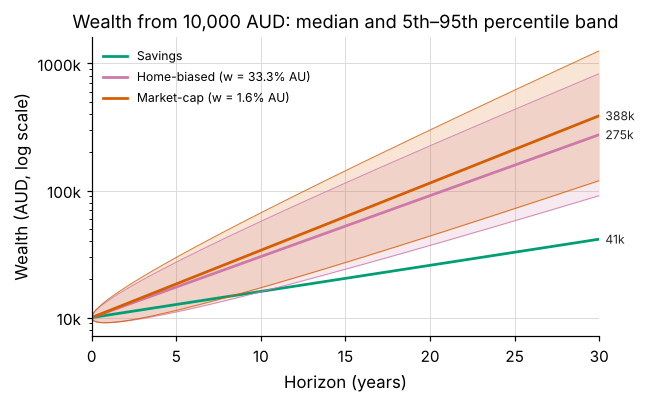

In [9]:
tg = np.linspace(0, 30, 301)
fan = ["Savings", "Home-biased", "Market-cap"]
fig, ax = plt.subplots(figsize=(6.0, 3.8))
for p in fan:
    mp, sp = port_tab.loc[p, "mu_p"], port_tab.loc[p, "sigma_p"]
    med = gu.wealth_quantile(W0, mp, sp, tg, 0.5)
    if sp > 0:
        ax.fill_between(tg, gu.wealth_quantile(W0, mp, sp, tg, 0.05), gu.wealth_quantile(W0, mp, sp, tg, 0.95),
                        color=COL[p], alpha=0.16, lw=0)
        for q in (0.05, 0.95):
            ax.plot(tg, gu.wealth_quantile(W0, mp, sp, tg, q), color=COL[p], lw=0.7, alpha=0.8)
    w_txt = "" if p == "Savings" else f" (w = {100 * PORTS[p][1]:.1f}% AU)"
    ax.plot(tg, med, color=COL[p], lw=1.8, label=f"{p}{w_txt}")
    ax.annotate(f"{med[-1] / 1000:,.0f}k", (30, med[-1]), xytext=(4, 0), textcoords="offset points",
                fontsize=8, va="center", color="0.15")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1000:g}k"))
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlim(0, 30)
ax.set_xlabel("Horizon (years)")
ax.set_ylabel("Wealth (AUD, log scale)")
ax.set_title("Wealth from 10,000 AUD: median and 5th–95th percentile band")
ax.legend(loc="upper left", fontsize=8)
fig.tight_layout()
gu.savefig(fig, "fig10_wealth_fan")
plt.show()

## 4. Estimation risk

The drifts are estimated imprecisely (notebook 03). The shortfall probabilities are recomputed with
$\mu_A$ and $\mu_G$ both at the lower ends and both at the upper ends of their i.i.d. 95% confidence
intervals (Table 3), holding $\sigma_A$, $\sigma_G$, $\rho$ and the weights fixed (including $w^*$). Because the
shortfall probability falls as either drift rises, these two corners bound it over the whole rectangle of
the two intervals.

As a Bayesian alternative, the **posterior predictive** shortfall probability averages the GBM shortfall
probability over the posterior draws of $(\nu_A, \nu_G, \sigma_A, \sigma_G, \rho)$ from notebook 03b, which
integrates over parameter uncertainty instead of taking its extremes.

**Fig 11** shows the shortfall probability against horizon (1–30 years), one panel per risky portfolio: the
point estimate (solid), the band between the two corner cases (shaded), and the posterior predictive value
(dashed).

In [10]:
mu_lo = {"A": table3.loc["mu_AU", "iid lo"], "G": table3.loc["mu_GL", "iid lo"]}
mu_hi = {"A": table3.loc["mu_AU", "iid hi"], "G": table3.loc["mu_GL", "iid hi"]}
print(f"mu_A 95% CI [{mu_lo['A']:.2%}, {mu_hi['A']:.2%}], mu_G 95% CI [{mu_lo['G']:.2%}, {mu_hi['G']:.2%}]")

post_mu_a = post.nu_AU + post.sigma_AU**2 / 2
post_mu_g = post.nu_GL + post.sigma_GL**2 / 2
tgrid = np.linspace(1, 30, 117)


def shortfall_curve(p, ma, mg, T):
    pi, w, _ = PORTS[p]
    mp, sp = gu.portfolio_params(pi, w, ma, mg, s_a, s_g, rho, r)
    return gu.shortfall_prob(mp, sp, r, T)


def predictive_shortfall(p, T):
    pi, w, _ = PORTS[p]
    mp, sp = gu.portfolio_params(pi, w, post_mu_a.to_numpy(), post_mu_g.to_numpy(), post.sigma_AU.to_numpy(),
                                 post.sigma_GL.to_numpy(), post.rho.to_numpy(), r)
    return float(np.mean(gu.shortfall_prob(mp, sp, r, T)))


est_rows = []
for p in RISKY:
    for T in H:
        est_rows.append({"portfolio": p, "T": int(T),
                         "shortfall (point)": float(shortfall_curve(p, mu_a, mu_g, T)),
                         "shortfall (mu at CI low)": float(shortfall_curve(p, mu_lo["A"], mu_lo["G"], T)),
                         "shortfall (mu at CI high)": float(shortfall_curve(p, mu_hi["A"], mu_hi["G"], T)),
                         "shortfall (posterior predictive)": predictive_shortfall(p, T)})
est_risk = pd.DataFrame(est_rows).set_index(["portfolio", "T"])
est_risk.to_csv(gu.TAB_DIR / "portfolio_estimation_risk.csv")
est_risk.style.format("{:.3f}")

mu_A 95% CI [0.91%, 17.48%], mu_G 95% CI [5.69%, 20.53%]


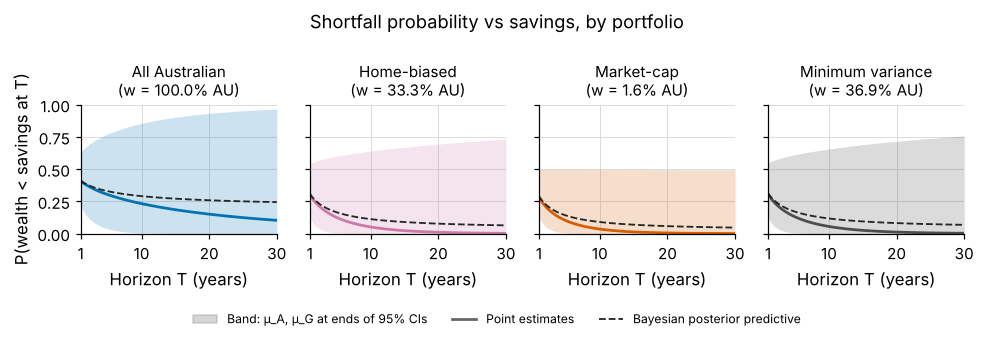

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(9.0, 3.0), sharey=True)
for ax, p in zip(axes, RISKY):
    ax.fill_between(tgrid, shortfall_curve(p, mu_hi["A"], mu_hi["G"], tgrid),
                    shortfall_curve(p, mu_lo["A"], mu_lo["G"], tgrid), color=COL[p], alpha=0.2, lw=0)
    ax.plot(tgrid, shortfall_curve(p, mu_a, mu_g, tgrid), color=COL[p], lw=1.8)
    ax.plot(tgrid, [predictive_shortfall(p, T) for T in tgrid], color="0.15", lw=1.2, ls="--")
    ax.set_xlim(1, 30)
    ax.set_ylim(0, 1)
    ax.set_xticks([1, 10, 20, 30])
    ax.set_title(f"{p}\n(w = {100 * PORTS[p][1]:.1f}% AU)", fontsize=10)
    ax.set_xlabel("Horizon T (years)")
axes[0].set_ylabel("P(wealth < savings at T)")
handles = [plt.Rectangle((0, 0), 1, 1, color="0.6", alpha=0.4),
           plt.Line2D([], [], color="0.4", lw=1.8), plt.Line2D([], [], color="0.15", lw=1.2, ls="--")]
fig.legend(handles, ["Band: μ_A, μ_G at ends of 95% CIs", "Point estimates", "Bayesian posterior predictive"],
           loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.01))
fig.suptitle("Shortfall probability vs savings, by portfolio", fontsize=12)
fig.tight_layout(rect=(0, 0.08, 1, 1))
gu.savefig(fig, "fig11_shortfall")
plt.show()

## 5. Model risk: block bootstrap without GBM

Terminal wealth is simulated without assuming GBM by resampling the historical daily returns in blocks of 20
trading days (100,000 paths, fixed seed). Both ETFs are resampled on the same days, which keeps their
correlation, fat tails and short-run volatility clustering within each block. Each portfolio is rebalanced
daily, as in the Monte Carlo check. The left tail (5th and 1st percentiles) of terminal wealth is compared
with the GBM values. The median is also shown: the bootstrap's typical growth is the historical average
daily-rebalanced log return, which is close to, but not identical to, the GBM $\nu_p$.

In [12]:
port_hist = np.vstack([gu.portfolio_daily_log_returns(X, PORTS[p][0], PORTS[p][1], r, DT) for p in RISKY])
rng = np.random.default_rng(cfg.SEED)
boot_logw = {}
for T in [10, 30]:
    boot_logw[T] = gu.block_bootstrap_log_wealth(port_hist, int(T * cfg.TRADING_DAYS), cfg.BLOCK_LENGTH,
                                                 cfg.N_BOOT_PATHS, rng)
mr_rows = []
for i, p in enumerate(RISKY):
    mp, sp = port_tab.loc[p, "mu_p"], port_tab.loc[p, "sigma_p"]
    for T in [10, 30]:
        Wb = W0 * np.exp(boot_logw[T][i])
        row = {"portfolio": p, "T": T}
        for q, name in [(0.01, "p1"), (0.05, "p5"), (0.5, "median")]:
            row[f"{name} GBM"] = gu.wealth_quantile(W0, mp, sp, T, q)
            row[f"{name} bootstrap"] = np.quantile(Wb, q)
        row["shortfall GBM"] = float(gu.shortfall_prob(mp, sp, r, T))
        row["shortfall bootstrap"] = (Wb < W0 * np.exp(r * T)).mean()
        mr_rows.append(row)
model_risk = pd.DataFrame(mr_rows).set_index(["portfolio", "T"])
model_risk["p5 ratio (boot/GBM)"] = model_risk["p5 bootstrap"] / model_risk["p5 GBM"]
model_risk["p1 ratio (boot/GBM)"] = model_risk["p1 bootstrap"] / model_risk["p1 GBM"]
model_risk.to_csv(gu.TAB_DIR / "portfolio_model_risk.csv")
print("Historical (daily-rebalanced) mean log return vs GBM nu_p, % per year:")
print(pd.DataFrame({"historical": 100 * port_hist.mean(axis=1) / DT,
                    "GBM nu_p": 100 * port_tab.loc[RISKY, "nu_p"].to_numpy()}, index=RISKY).round(3))
model_risk.style.format({c: "{:,.0f}" for c in model_risk.columns if "ratio" not in c and "shortfall" not in c}
                        | {"shortfall GBM": "{:.3f}", "shortfall bootstrap": "{:.3f}",
                           "p5 ratio (boot/GBM)": "{:.3f}", "p1 ratio (boot/GBM)": "{:.3f}"})

Historical (daily-rebalanced) mean log return vs GBM nu_p, % per year:
                  historical  GBM nu_p
All Australian         8.117     8.117
Home-biased           11.050    11.050
Market-cap            12.194    12.194
Minimum variance      10.911    10.911


**Fig 12** shows the 10-year terminal wealth distribution under GBM (line) and the block bootstrap
(histogram) for the home-biased and market-cap portfolios, on a log wealth axis. Vertical lines mark the
5th (dashed) and 1st (dotted) percentiles for each method; the region below the GBM 5th percentile is shaded.

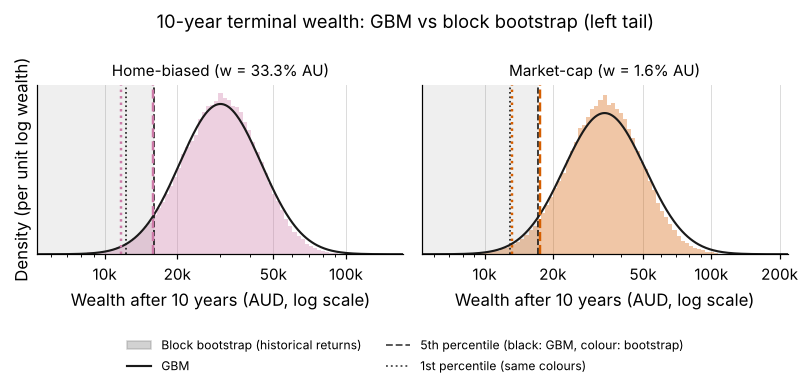

In [13]:
T = 10
fig, axes = plt.subplots(1, 2, figsize=(7.5, 3.4), sharey=True)
for ax, p in zip(axes, ["Home-biased", "Market-cap"]):
    i = RISKY.index(p)
    lw = boot_logw[T][i] + np.log(W0)
    mp, sp = port_tab.loc[p, "mu_p"], port_tab.loc[p, "sigma_p"]
    m_ln, s_ln = np.log(W0) + (mp - sp**2 / 2) * T, sp * np.sqrt(T)
    edges = np.linspace(m_ln - 4.5 * s_ln, m_ln + 4.5 * s_ln, 90)
    dens, _ = np.histogram(lw, bins=edges, density=True)
    ax.stairs(dens, np.exp(edges), fill=True, color=COL[p], alpha=0.35, label="Block bootstrap")
    g = np.linspace(edges[0], edges[-1], 400)
    ax.plot(np.exp(g), stats.norm.pdf(g, m_ln, s_ln), color="0.1", lw=1.4, label="GBM")
    p5_gbm = np.exp(m_ln + stats.norm.ppf(0.05) * s_ln)
    ax.axvspan(np.exp(edges[0]), p5_gbm, color="0.5", alpha=0.12, lw=0)
    for q, ls in [(0.05, "--"), (0.01, ":")]:
        ax.axvline(np.exp(m_ln + stats.norm.ppf(q) * s_ln), color="0.1", ls=ls, lw=1.1)
        ax.axvline(np.exp(np.quantile(lw, q)), color=COL[p], ls=ls, lw=1.6)
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(mticker.LogLocator(base=10, subs=[1, 2, 5]))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v / 1000:g}k"))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())
    ax.set_xlim(np.exp(edges[0]), np.exp(edges[-1]))
    ax.set_title(f"{p} (w = {100 * PORTS[p][1]:.1f}% AU)", fontsize=10)
    ax.set_xlabel(f"Wealth after {T} years (AUD, log scale)")
    ax.set_yticks([])
axes[0].set_ylabel("Density (per unit log wealth)")
from matplotlib.lines import Line2D
handles = [plt.Rectangle((0, 0), 1, 1, color="0.5", alpha=0.35), Line2D([], [], color="0.1", lw=1.4),
           Line2D([], [], color="0.3", ls="--"), Line2D([], [], color="0.3", ls=":")]
fig.legend(handles, ["Block bootstrap (historical returns)", "GBM",
                     "5th percentile (black: GBM, colour: bootstrap)", "1st percentile (same colours)"],
           loc="lower center", ncol=2, fontsize=8, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("10-year terminal wealth: GBM vs block bootstrap (left tail)", fontsize=12)
fig.tight_layout(rect=(0, 0.13, 1, 1))
gu.savefig(fig, "fig12_gbm_vs_bootstrap")
plt.show()

## 6. Drawdowns

The maximum drawdown is the largest fall from a running peak of wealth. For each risky portfolio it is
computed (i) on the historical daily-rebalanced portfolio over the sample, and (ii) on the simulated GBM
paths of Section 3 over a horizon of the same length as the sample, and over 30 years. The table reports the
median and 95th percentile of the simulated maximum drawdown and the share of simulated paths whose
drawdown over the sample length is at least as deep as the historical one.

In [14]:
dd_rows = []
for i, p in enumerate(RISKY):
    hist_path = np.concatenate([[0.0], np.cumsum(port_hist[i])])
    mdd_hist = float(gu.max_drawdown(hist_path))
    dd_s, dd_30 = mc_dd[p][n_hist], mc_dd[p][n_steps]
    dd_rows.append({"portfolio": p, "historical MDD": mdd_hist,
                    f"GBM MDD median ({n_hist / cfg.TRADING_DAYS:.1f}y)": np.median(dd_s),
                    f"GBM MDD 95th pct ({n_hist / cfg.TRADING_DAYS:.1f}y)": np.quantile(dd_s, 0.95),
                    "P(GBM MDD >= historical)": (dd_s >= mdd_hist).mean(),
                    "GBM MDD median (30y)": np.median(dd_30), "GBM MDD 95th pct (30y)": np.quantile(dd_30, 0.95)})
drawdowns = pd.DataFrame(dd_rows).set_index("portfolio")
drawdowns.to_csv(gu.TAB_DIR / "portfolio_drawdowns.csv")
hist_peak_dates = {}
for i, p in enumerate(RISKY):
    path = pd.Series(np.cumsum(port_hist[i]), index=daily.index)
    trough = (path - path.cummax()).idxmin()
    hist_peak_dates[p] = (path.loc[:trough].idxmax().date(), trough.date())
print("Historical peak -> trough dates:", hist_peak_dates)
drawdowns.style.format("{:.1%}")

Historical peak -> trough dates: {'All Australian': (datetime.date(2020, 2, 20), datetime.date(2020, 3, 23)), 'Home-biased': (datetime.date(2020, 2, 20), datetime.date(2020, 3, 23)), 'Market-cap': (datetime.date(2020, 2, 21), datetime.date(2020, 3, 23)), 'Minimum variance': (datetime.date(2020, 2, 20), datetime.date(2020, 3, 23))}


,historical MDD,GBM MDD median (12.0y),GBM MDD 95th pct (12.0y),P(GBM MDD >= historical),GBM MDD median (30y),GBM MDD 95th pct (30y)
portfolio,,,,,,
All Australian,35.8%,28.7%,45.7%,21.8%,35.7%,52.8%
Home-biased,27.5%,20.3%,32.1%,13.5%,24.8%,36.5%
Market-cap,23.6%,21.1%,33.1%,33.8%,25.7%,37.5%
Minimum variance,27.9%,20.4%,32.2%,12.7%,24.9%,36.7%


## 7. Table 4 — portfolio outcomes at 10 and 30 years

For each portfolio: $\mu_p$, $\sigma_p$, median and 5th-percentile terminal wealth from $W_0$ = 10,000 AUD,
and the shortfall probability against savings at the point estimates, with the range from the drift
confidence-interval ends and the Bayesian posterior predictive value.

In [15]:
t4_rows = []
for p in PORTS:
    for T in [10, 30]:
        a = analytic.loc[(p, T)]
        row = {"portfolio": p, "T": T, "mu_p": port_tab.loc[p, "mu_p"], "sigma_p": port_tab.loc[p, "sigma_p"],
               "median": a["median"], "p5": a["p5"], "shortfall": a["shortfall"]}
        if p in RISKY:
            e = est_risk.loc[(p, T)]
            row.update({"shortfall low": e["shortfall (mu at CI high)"], "shortfall high": e["shortfall (mu at CI low)"],
                        "shortfall predictive": e["shortfall (posterior predictive)"]})
        t4_rows.append(row)
table4 = pd.DataFrame(t4_rows).set_index(["portfolio", "T"])
table4.to_csv(gu.TAB_DIR / "portfolio_outcomes.csv")


def f_rng(lo, hi):
    return "--" if pd.isna(lo) else f"[{lo:.2f}, {hi:.2f}]"


tex = pd.DataFrame({
    "$T$": [t for _, t in table4.index],
    r"$\mu_p$ (\%)": [f"{100 * v:.2f}" for v in table4["mu_p"]],
    r"$\sigma_p$ (\%)": [f"{100 * v:.2f}" for v in table4["sigma_p"]],
    "Median": [f"{v:,.0f}" for v in table4["median"]],
    "5th pct": [f"{v:,.0f}" for v in table4["p5"]],
    "Shortfall": ["--" if pd.isna(v) else f"{v:.2f}" for v in table4["shortfall"]],
    "Range (CI ends)": [f_rng(lo, hi) for lo, hi in zip(table4["shortfall low"], table4["shortfall high"])],
    "Predictive": ["--" if pd.isna(v) else f"{v:.2f}" for v in table4["shortfall predictive"]],
}, index=[p for p, _ in table4.index])
tex.to_latex(gu.TAB_DIR / "portfolio_outcomes.tex", escape=False, column_format="lrrrrrrrr",
             caption=(f"Portfolio outcomes under GBM from $W_0$ = 10,000 AUD ($r$ = {100 * r:.2f}\\% continuously "
                      "compounded). Median and 5th percentile of terminal wealth (AUD). Shortfall: "
                      "$\\mathbb{P}(W_T < W_0e^{rT})$ at the point estimates; range with $\\mu_A,\\mu_G$ at the "
                      "ends of their 95\\% confidence intervals; predictive: averaged over the posterior "
                      "of notebook 03b. Weights: home-biased $w=1/3$, market-cap $w=1.6\\%$, minimum variance "
                      f"$w^*={100 * w_star_used:.1f}\\%$."),
             label="tab:portfolios")
table4.style.format({"mu_p": "{:.2%}", "sigma_p": "{:.2%}", "median": "{:,.0f}", "p5": "{:,.0f}",
                     "shortfall": "{:.3f}", "shortfall low": "{:.3f}", "shortfall high": "{:.3f}",
                     "shortfall predictive": "{:.3f}"}, na_rep="--")

## 8. Measure

All results in this notebook are under the real-world measure $\mathbb{P}$, with drifts estimated from
historical returns. Under the risk-neutral measure $\mathbb{Q}$ every traded portfolio drifts at the
risk-free rate $r$, so $\mu_p = r$ for every $\pi$ and $w$, and the shortfall probability
$\Phi(\tfrac12\sigma_p\sqrt T)$ exceeds one half and grows with volatility and horizon for every equity
portfolio. $\mathbb{Q}$ is the right measure for pricing, but its probabilities say nothing about how an
investor's wealth is likely to turn out, which is the question here.